# 05 · Immunotherapy (ICI) cohorts: TLS score vs response and survival

The frozen model (notebook 03, no retraining) scores bulk RNA-seq of ICI-treated patients. Baselines: **Cabrita** TLS signature (Nature 2020), **12-chemokine** (Coppola, AJP 2011), **TLS imprint** (Meylan, Immunity 2022; 29 genes), all ssGSEA on log2(TPM+1).

* Every score is z-scored **within cohort** → HR / OR per 1 SD.
* Per diagnosis and pooled (*All*): **Cox** for OS / PFS stratified by cohort; **logistic** for response = ORR from RECIST (CR/PR vs SD/PD; study-annotated R/NR only where RECIST is missing) and DCR (CR/PR/SD vs PD) with cohort fixed effects.
* Confounders in every model: ICI class, age, sex, stage, site (primary / metastasis), location; missing → own level ('unknown'; age: median + missing indicator); covariates without variation inside cohorts are dropped.
* One model per score. **ΔC-index / ΔAUC** (ours − signature, and score − covariates-only) with a paired bootstrap (patients resampled within cohort, all models refit).
* Subset with **TMB-high (≥ 10 mut/Mb)** and **PD-L1 IHC (TC0/1/2+)**: same models with both added — does the TLS score add discrimination beyond TMB + PD-L1?

Expression and per-patient scores stay local (`data/private/ici/`); only aggregates are written to `results/ici/`.

In [1]:
import logging, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
(ROOT / "results").mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(ROOT / "results" / "notebooks.log")],
                    force=True)
for noisy in ("anndata", "fsspec", "matplotlib", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tls_model import pipeline
cfg = pipeline.load_config()
paths = {k: ROOT / v for k, v in cfg["paths"].items()}
FIG = paths["results"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Load cohorts, score the TLS model and the baseline signatures

In [2]:
import json, pickle
from tls_model import io_ici, io_bulk, ici_report

ICI = cfg["ici"]
OUT = paths["results"] / "ici"; OUT.mkdir(parents=True, exist_ok=True)
PARTS = paths["processed"] / "ici_parts"
expr, clin = io_ici.load_cohorts(ROOT / ICI["dir"], ICI["tmb_count_scale"])
meta = json.loads((paths["processed"] / "meta.json").read_text(encoding="utf-8"))
with open(ROOT / "models" / "tls_model.pkl", "rb") as handle:
    saved = pickle.load(handle)
p_tls = io_ici.score_tls(expr, meta, saved)
sigs = io_ici.baseline_signatures(io_bulk.load_signatures(paths["bulk_public"]))
print({name: f"{sum(g in set(expr.columns) for g in genes)}/{len(genes)} genes present" for name, genes in sigs.items()})
sig_scores = io_ici.score_signatures(expr, sigs)
df = ici_report.analysis_frame(clin, p_tls, sig_scores)
pd.concat([clin[["dataset", "cohort", "diagnosis"]], p_tls, sig_scores], axis=1).to_csv(ROOT / ICI["dir"] / "scores.tsv", sep="\t")
SIGS = list(sigs)
SCORES = [ici_report.OURS] + SIGS + [None]   # None = covariates-only model
print(len(clin), "samples loaded |", len(df), "ICI-treated, included histology")

2026-10-09 12:48:39,033 INFO tls_model.io_ici INOVA_Lung_Subramanian: 38 samples, 38 with ICI


2026-10-09 12:48:39,995 INFO tls_model.io_ici PUB_BLCA_Mariathasan_EGAS00001002556: 347 samples, 347 with ICI


2026-10-09 12:48:41,003 INFO tls_model.io_ici PUB_ccRCC_Immotion150_and_151_ICI: 560 samples, 560 with ICI


2026-10-09 12:48:41,773 INFO tls_model.io_ici PUB_ccRCC_Immotion150_and_151_TKI: 486 samples, 0 with ICI


2026-10-09 12:48:42,181 INFO tls_model.io_ici PUB_COREAD_ImmunoMSI: 108 samples, 108 with ICI


...

2026-10-09 12:48:51,610 INFO tls_model.io_ici WU_ccRCC_RCCTC_ICI: 37 samples, 37 with ICI


2026-10-09 12:48:51,931 INFO tls_model.io_ici WU_ccRCC_RCCTC_TKI: 42 samples, 0 with ICI


2026-10-09 12:48:53,211 INFO tls_model.io_ici total 3746 samples (0 dropped as duplicates), 20062 genes


{'Cabrita (TLS_SKCM)': '9/9 genes present', '12-chemokine (TLS_Chem)': '12/12 genes present', 'TLS imprint (Meylan 2022)': '27/29 genes present'}


3746 samples loaded | 2689 ICI-treated, included histology


## Cohorts and coverage (aggregates)

In [3]:
cohorts = df.groupby(["diagnosis", "cohort"]).agg(
    n=("sample", "size"), regimen=("icb_class", lambda s: ", ".join(sorted(s.dropna().unique()))),
    os=("os", "count"), pfs=("pfs", "count"), response=("response", "count"), dcr=("dcr", "count"),
    response_from=("response_source", lambda s: ", ".join(sorted(s.dropna().unique()))))
cohorts.to_csv(OUT / "cohorts.tsv", sep="\t")
g = df.groupby("diagnosis")
pct = lambda c: g[c].apply(lambda s: round(100 * s.notna().mean()))
coverage = pd.DataFrame({
    "n": g.size(), "cohorts": g["cohort"].nunique(),
    "OS n / events": g["os"].count().astype(str) + " / " + g["os_event"].sum().astype(int).astype(str),
    "PFS n / events": g["pfs"].count().astype(str) + " / " + g["pfs_event"].sum().astype(int).astype(str),
    "response n / R": g["response"].count().astype(str) + " / " + g["response"].sum().astype(int).astype(str),
    "DCR n / DC": g["dcr"].count().astype(str) + " / " + g["dcr"].sum().astype(int).astype(str),
    "age %": pct("age"), "sex %": pct("sex"), "stage %": pct("stage"), "site %": pct("site"), "location %": pct("location"),
    "TMB-high n": g["tmb_high"].count(), "PD-L1 n": g["pdl1_tc"].count(),
})
coverage.to_csv(OUT / "coverage.tsv", sep="\t")
coverage

,n,cohorts,OS n / events,PFS n / events,response n / R,DCR n / DC,age %,sex %,stage %,site %,location %,TMB-high n,PD-L1 n
diagnosis,,,,,,,,,,,,,
BLCA,347,1,347 / 231,0 / 0,298 / 68,298 / 131,0,100,0,0,0,271,346
COREAD,190,2,0 / 0,188 / 39,183 / 111,183 / 165,0,100,0,0,0,0,0
ESGA,34,1,0 / 0,0 / 0,34 / 11,34 / 20,0,100,0,0,0,0,0
NSCLC,606,8,573 / 365,606 / 490,571 / 236,205 / 134,46,46,29,0,0,141,198
SKCM,348,10,249 / 124,174 / 113,330 / 138,298 / 168,49,59,34,59,62,0,0
ccRCC,1164,7,250 / 147,977 / 585,765 / 254,765 / 547,33,96,17,52,0,0,36


## How similar are the scores? (Spearman, within diagnosis)

In [4]:
rho = df.groupby("diagnosis")[[ici_report.OURS] + SIGS].corr(method="spearman")[ici_report.OURS].unstack()[SIGS].round(2)
rho.to_csv(OUT / "score_correlation.tsv", sep="\t")
rho

,Cabrita (TLS_SKCM),12-chemokine (TLS_Chem),TLS imprint (Meylan 2022)
diagnosis,,,
BLCA,0.62,0.62,0.83
COREAD,0.54,0.21,0.64
ESGA,0.49,0.24,0.72
NSCLC,0.64,0.52,0.69
SKCM,0.55,0.57,0.75
ccRCC,0.35,0.54,0.75


## Main analysis: every diagnosis × endpoint × score

In [5]:
assoc, delta = ici_report.run_analysis(df, "main", SCORES, ICI["covariates"], ici_report.main_pairs(SIGS),
                                       PARTS, ICI["n_boot"], ICI["seed"])
assoc.to_csv(OUT / "assoc_main.tsv", sep="\t", index=False)
delta.to_csv(OUT / "delta_main.tsv", sep="\t", index=False)
view = assoc[assoc["score"] != "covariates only"].assign(
    effect=lambda t: t.apply(lambda r: f"{r.estimate:.2f} [{r.lo:.2f}, {r.hi:.2f}]" if pd.notna(r.estimate) else r.note, axis=1))
view.pivot_table(index=["endpoint", "diagnosis"], columns="score", values="effect", aggfunc="first")

2026-10-09 12:49:11,250 INFO tls_model.ici_report [1/28] main BLCA OS SKIP (cached)


2026-10-09 12:49:11,258 INFO tls_model.ici_report [2/28] main BLCA PFS SKIP (cached)


2026-10-09 12:49:11,265 INFO tls_model.ici_report [3/28] main BLCA Response SKIP (cached)


2026-10-09 12:49:11,272 INFO tls_model.ici_report [4/28] main BLCA DCR SKIP (cached)


2026-10-09 12:49:11,280 INFO tls_model.ici_report [5/28] main COREAD OS SKIP (cached)


...

2026-10-09 12:49:11,423 INFO tls_model.ici_report [25/28] main All OS SKIP (cached)


2026-10-09 12:49:11,431 INFO tls_model.ici_report [26/28] main All PFS SKIP (cached)


2026-10-09 12:49:11,437 INFO tls_model.ici_report [27/28] main All Response SKIP (cached)


2026-10-09 12:49:11,445 INFO tls_model.ici_report [28/28] main All DCR SKIP (cached)


score              12-chemokine (TLS_Chem)  Cabrita (TLS_SKCM) TLS imprint (Meylan 2022)    TLS model (ours)
endpoint diagnosis                                                                                          
DCR      All             1.19 [1.07, 1.32]   1.17 [1.04, 1.31]         1.10 [0.99, 1.22]   1.08 [0.97, 1.20]
         BLCA            1.37 [1.08, 1.72]   1.20 [0.94, 1.53]         1.16 [0.92, 1.47]   1.30 [1.04, 1.64]
         COREAD          0.98 [0.60, 1.61]   1.33 [0.78, 2.26]         1.08 [0.66, 1.76]   1.24 [0.75, 2.04]
         ESGA            2.14 [0.97, 4.70]   1.18 [0.59, 2.35]         1.99 [0.87, 4.54]   1.96 [0.86, 4.44]
         NSCLC           1.06 [0.77, 1.46]   1.20 [0.85, 1.67]         1.17 [0.86, 1.60]   0.95 [0.70, 1.30]
         SKCM            1.26 [0.98, 1.62]   1.19 [0.91, 1.55]         1.13 [0.88, 1.45]   1.01 [0.78, 1.30]
         ccRCC           1.11 [0.94, 1.30]   1.15 [0.95, 1.38]         1.02 [0.87, 1.21]   0.97 [0.82, 1.15]
OS       All             0.86 [0.80, 0.91]   0.90 [0.84, 0.97]         0.91 [0.85, 0.97]   0.92 [0.86, 0.99]
         BLCA            0.88 [0.78, 1.00]   0.99 [0.86, 1.15]         0.95 [0.83, 1.08]   0.90 [0.79, 1.03]
         COREAD         too few events (0)  too few events (0)        too few events (0)  too few events (0)
         ESGA           too few events (0)  too few events (0)        too few events (0)  too few events (0)
         NSCLC           0.82 [0.74, 0.91]   0.90 [0.81, 1.00]         0.88 [0.79, 0.98]   0.92 [0.83, 1.02]
         SKCM            0.67 [0.55, 0.81]   0.72 [0.58, 0.89]         0.69 [0.58, 0.83]   0.73 [0.59, 0.90]
         ccRCC           1.06 [0.91, 1.24]   0.87 [0.72, 1.05]         1.08 [0.91, 1.27]   1.07 [0.92, 1.24]
PFS      All             0.87 [0.82, 0.92]   0.90 [0.85, 0.96]         0.91 [0.86, 0.96]   0.94 [0.89, 0.99]
         BLCA           too few events (0)  too few events (0)        too few events (0)  too few events (0)
         COREAD          0.87 [0.63, 1.18]   0.98 [0.72, 1.35]         1.01 [0.74, 1.38]   0.82 [0.60, 1.12]
         ESGA           too few events (0)  too few events (0)        too few events (0)  too few events (0)
         NSCLC           0.81 [0.75, 0.89]   0.88 [0.80, 0.97]         0.89 [0.81, 0.98]   0.93 [0.85, 1.02]
         SKCM            0.75 [0.61, 0.91]   0.73 [0.59, 0.92]         0.77 [0.64, 0.92]   0.93 [0.77, 1.14]
         ccRCC           0.93 [0.86, 1.01]   0.92 [0.83, 1.01]         0.94 [0.87, 1.01]   0.93 [0.86, 1.01]
Response All             1.33 [1.21, 1.46]   1.11 [1.01, 1.23]         1.15 [1.04, 1.26]   1.15 [1.05, 1.26]
         BLCA            1.26 [0.96, 1.66]   0.82 [0.59, 1.12]         0.93 [0.71, 1.21]   1.06 [0.82, 1.39]
         COREAD          1.24 [0.89, 1.71]   1.33 [0.94, 1.88]         0.94 [0.67, 1.30]   1.05 [0.76, 1.46]
         ESGA           6.00 [1.57, 23.01]   0.89 [0.43, 1.83]         1.39 [0.61, 3.15]   1.43 [0.65, 3.16]
         NSCLC           1.41 [1.17, 1.69]   1.13 [0.95, 1.35]         1.09 [0.91, 1.30]   1.06 [0.89, 1.26]
         SKCM            1.29 [1.01, 1.64]   1.13 [0.88, 1.45]         1.25 [0.98, 1.60]   1.04 [0.82, 1.32]
         ccRCC           1.29 [1.10, 1.51]   1.18 [0.98, 1.42]         1.28 [1.08, 1.52]   1.30 [1.11, 1.53]

## Forest plots

Left: HR (OS / PFS) or OR (response / DCR) per 1 SD with 95% CI. Right: ΔC-index / ΔAUC of the model with our score minus the model with each signature (same patients).

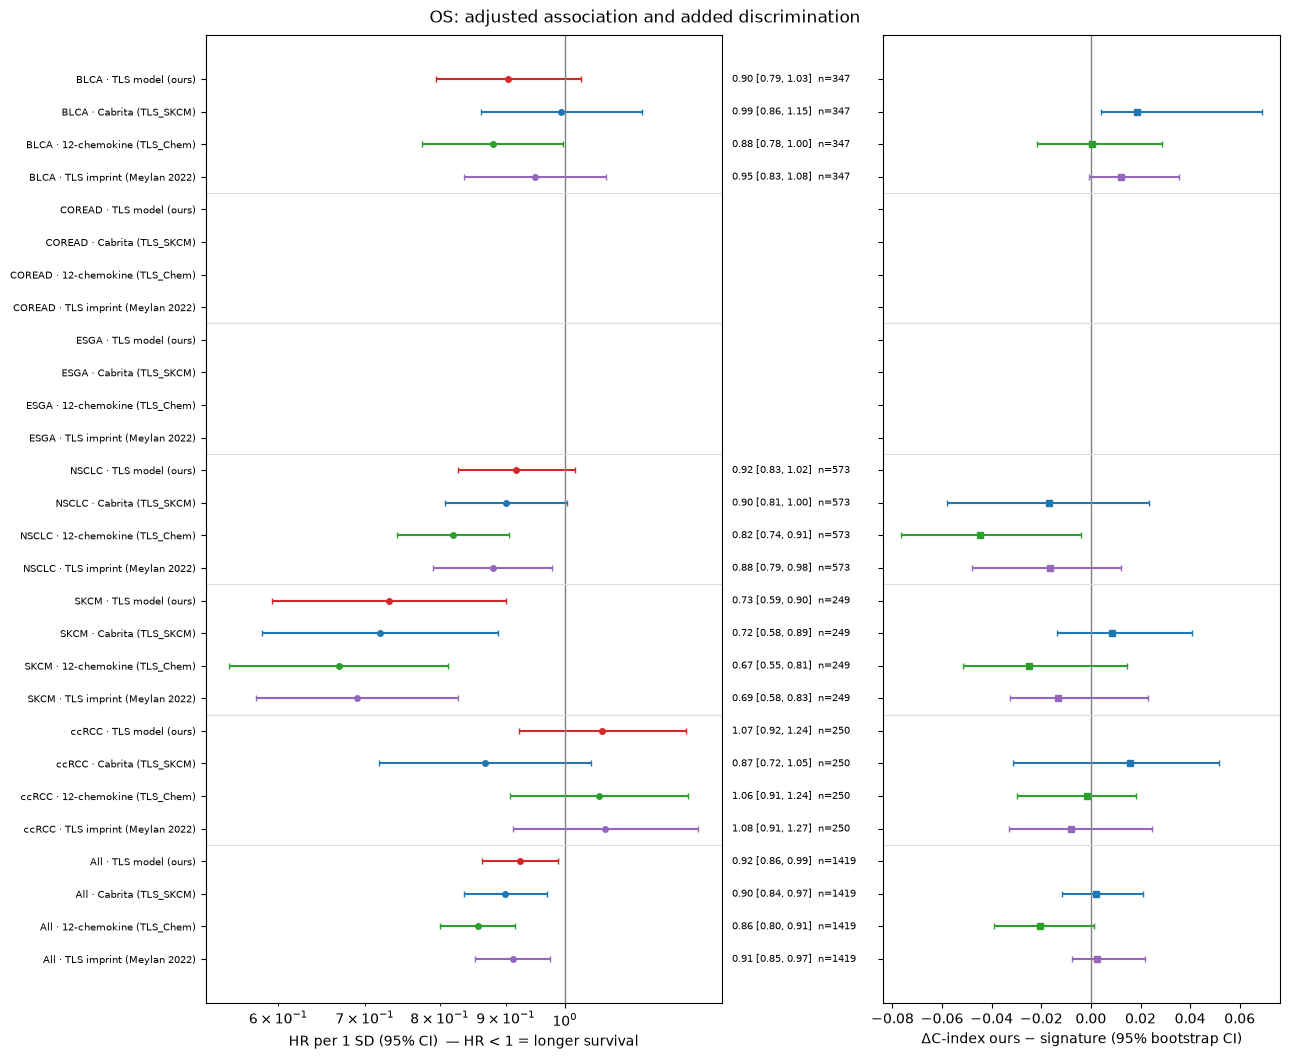

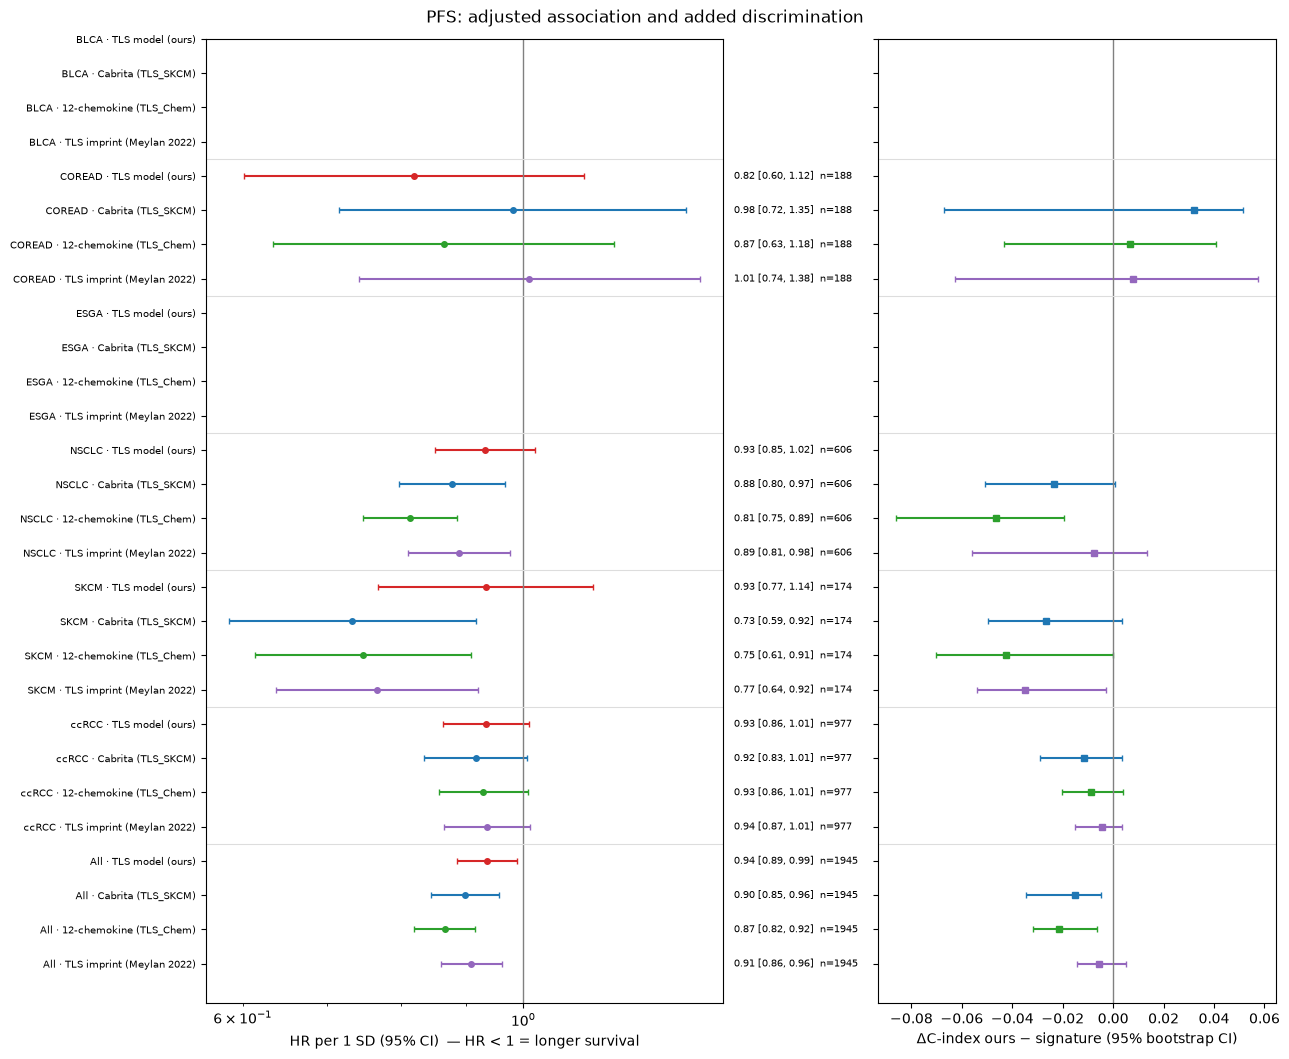

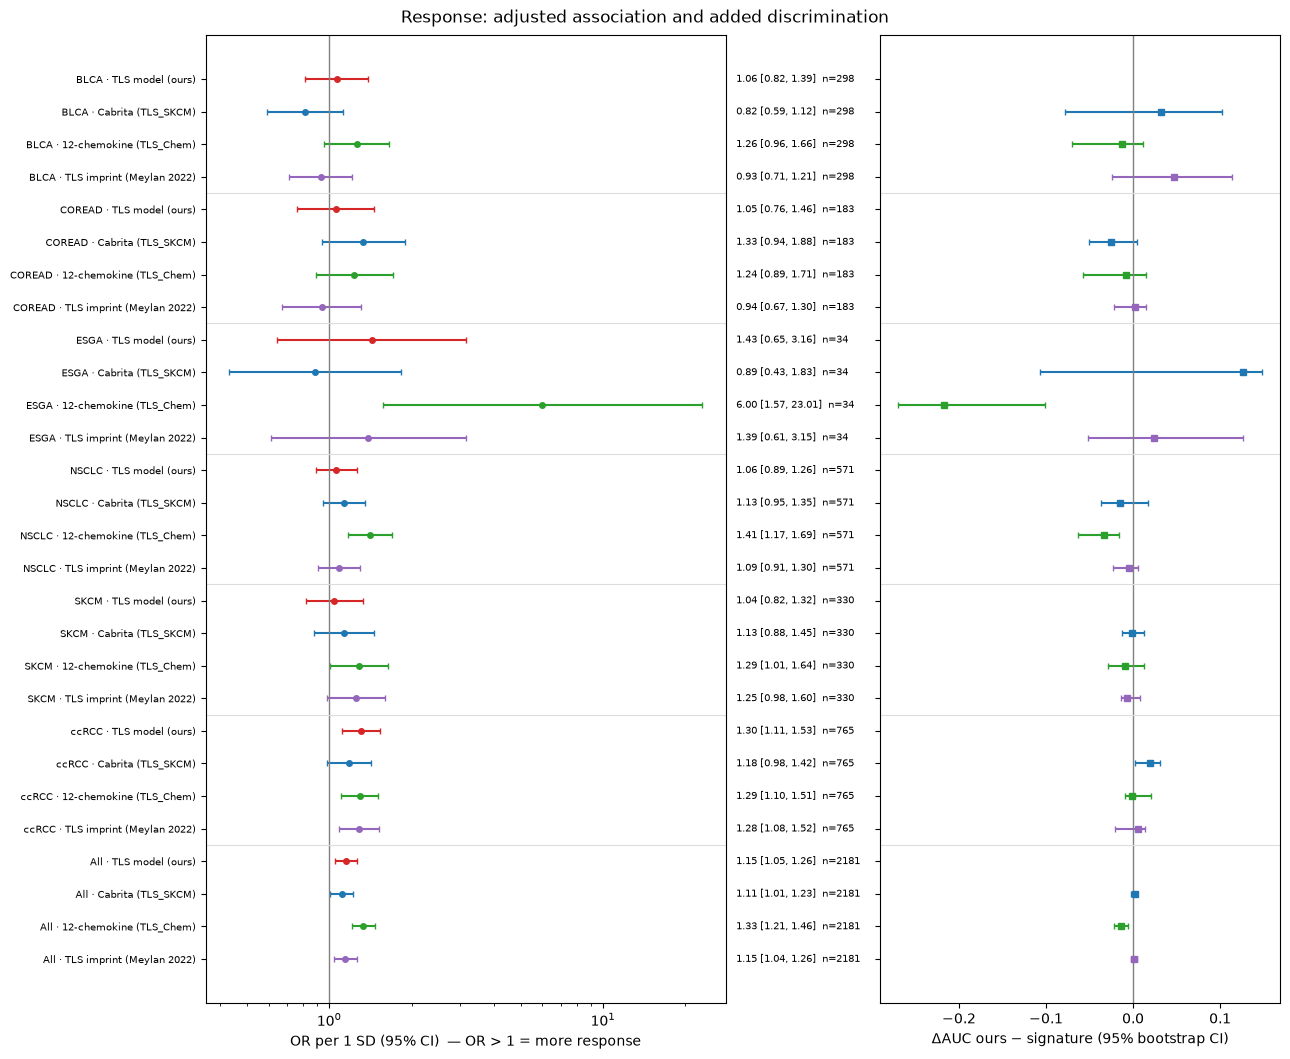

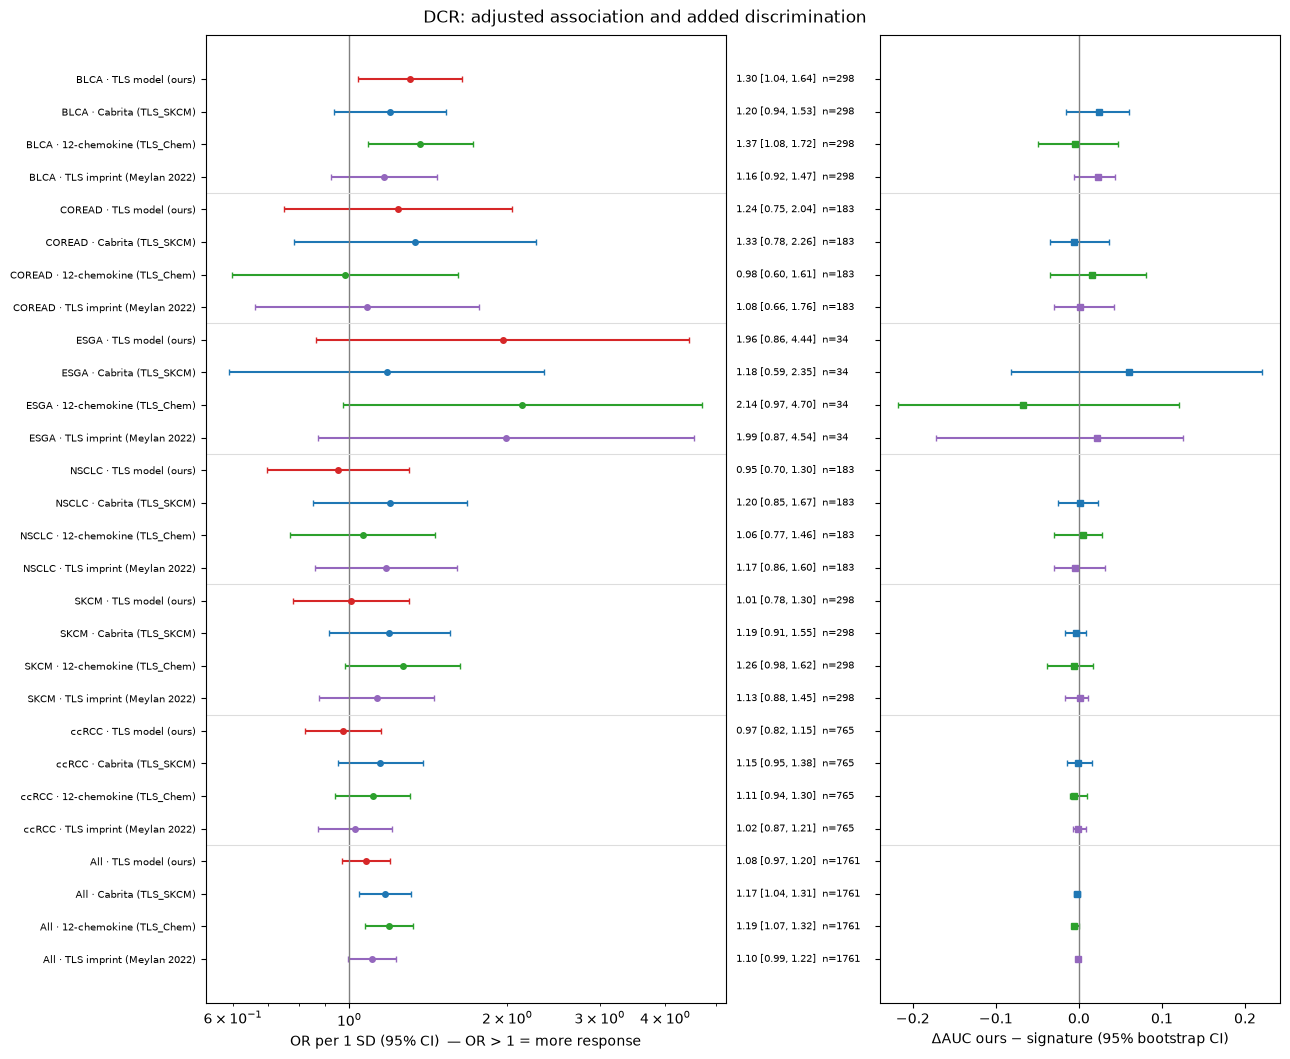

In [6]:
for endpoint in ici_report.ENDPOINTS:
    fig = ici_report.forest_plot(assoc, delta, endpoint, [ici_report.OURS] + SIGS)
    fig.savefig(FIG / f"05_forest_{endpoint}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Discrimination: ours vs signatures, and every score vs covariates only

In [7]:
fmt = lambda t: t.assign(delta=t.apply(lambda r: f"{r.delta:+.3f} [{r.delta_lo:+.3f}, {r.delta_hi:+.3f}]", axis=1))
print("ours − signature (C-index for OS / PFS, AUC for response / DCR)")
display(fmt(delta[delta["reference"] == ici_report.OURS]).pivot_table(index=["endpoint", "diagnosis"], columns="other", values="delta", aggfunc="first"))
print("score − covariates-only model")
display(fmt(delta[delta["other"] == "covariates only"]).pivot_table(index=["endpoint", "diagnosis"], columns="reference", values="delta", aggfunc="first"))

ours − signature (C-index for OS / PFS, AUC for response / DCR)


other               12-chemokine (TLS_Chem)       Cabrita (TLS_SKCM) TLS imprint (Meylan 2022)          covariates only
endpoint diagnosis                                                                                                     
DCR      All        -0.006 [-0.008, +0.000]  -0.003 [-0.005, +0.001]   -0.001 [-0.003, +0.002]  +0.001 [+0.000, +0.004]
         BLCA       -0.004 [-0.049, +0.047]  +0.024 [-0.016, +0.061]   +0.023 [-0.006, +0.044]  +0.074 [+0.020, +0.130]
         COREAD     +0.016 [-0.035, +0.080]  -0.006 [-0.034, +0.036]   +0.001 [-0.030, +0.042]  +0.011 [-0.005, +0.066]
         ESGA       -0.068 [-0.218, +0.121]  +0.061 [-0.082, +0.220]   +0.021 [-0.172, +0.125]  +0.107 [+0.032, +0.269]
         NSCLC      +0.005 [-0.030, +0.028]  +0.002 [-0.025, +0.023]   -0.004 [-0.029, +0.031]  +0.006 [-0.005, +0.037]
         SKCM       -0.006 [-0.038, +0.017]  -0.003 [-0.017, +0.009]   +0.001 [-0.017, +0.010]  -0.000 [-0.007, +0.019]
         ccRCC      -0.006 [-0.010, +0.010]  -0.001 [-0.015, +0.016]   -0.001 [-0.007, +0.008]  +0.000 [-0.001, +0.014]
OS       All        -0.020 [-0.039, +0.001]  +0.002 [-0.012, +0.021]   +0.002 [-0.008, +0.022]  +0.022 [+0.002, +0.043]
         BLCA       +0.001 [-0.022, +0.029]  +0.019 [+0.004, +0.069]   +0.012 [-0.001, +0.036]  +0.030 [+0.011, +0.057]
         NSCLC      -0.045 [-0.076, -0.004]  -0.017 [-0.058, +0.024]   -0.016 [-0.048, +0.012]  +0.013 [-0.011, +0.043]
         SKCM       -0.025 [-0.052, +0.014]  +0.008 [-0.014, +0.041]   -0.013 [-0.032, +0.023]  +0.052 [-0.004, +0.090]
         ccRCC      -0.002 [-0.030, +0.018]  +0.016 [-0.031, +0.052]   -0.008 [-0.033, +0.024]  +0.003 [-0.016, +0.036]
PFS      All        -0.021 [-0.032, -0.006]  -0.015 [-0.034, -0.005]   -0.006 [-0.014, +0.005]  -0.000 [-0.018, +0.017]
         COREAD     +0.007 [-0.043, +0.041]  +0.032 [-0.067, +0.051]   +0.008 [-0.063, +0.057]  +0.013 [-0.005, +0.057]
         NSCLC      -0.047 [-0.086, -0.019]  -0.023 [-0.051, +0.001]   -0.007 [-0.056, +0.013]  +0.019 [-0.010, +0.046]
         SKCM       -0.042 [-0.070, +0.000]  -0.027 [-0.049, +0.003]   -0.035 [-0.054, -0.003]  -0.001 [-0.007, +0.024]
         ccRCC      -0.009 [-0.020, +0.004]  -0.012 [-0.029, +0.004]   -0.005 [-0.015, +0.004]  +0.005 [-0.014, +0.018]
Response All        -0.014 [-0.022, -0.006]  +0.003 [-0.002, +0.005]   +0.001 [-0.002, +0.004]  +0.006 [+0.001, +0.013]
         BLCA       -0.013 [-0.070, +0.011]  +0.032 [-0.078, +0.102]   +0.047 [-0.024, +0.113]  +0.041 [-0.005, +0.081]
         COREAD     -0.008 [-0.058, +0.015]  -0.025 [-0.050, +0.005]   +0.003 [-0.021, +0.015]  +0.001 [-0.006, +0.028]
         ESGA       -0.217 [-0.270, -0.102]  +0.126 [-0.107, +0.148]   +0.024 [-0.052, +0.126]  +0.071 [+0.010, +0.198]
         NSCLC      -0.034 [-0.063, -0.016]  -0.015 [-0.037, +0.017]   -0.004 [-0.023, +0.006]  +0.004 [-0.008, +0.027]
         SKCM       -0.009 [-0.029, +0.013]  -0.001 [-0.013, +0.013]   -0.007 [-0.014, +0.008]  -0.003 [-0.002, +0.012]
         ccRCC      -0.001 [-0.010, +0.020]  +0.019 [+0.002, +0.031]   +0.006 [-0.020, +0.014]  +0.018 [+0.005, +0.041]

score − covariates-only model


reference           12-chemokine (TLS_Chem)       Cabrita (TLS_SKCM) TLS imprint (Meylan 2022)         TLS model (ours)
endpoint diagnosis                                                                                                     
DCR      All        +0.007 [+0.002, +0.010]  +0.004 [-0.000, +0.008]   +0.002 [+0.000, +0.006]  +0.001 [+0.000, +0.004]
         BLCA       +0.078 [+0.024, +0.102]  +0.050 [-0.001, +0.099]   +0.051 [+0.007, +0.094]  +0.074 [+0.020, +0.130]
         COREAD     -0.005 [-0.017, +0.039]  +0.017 [-0.004, +0.050]   +0.010 [-0.016, +0.039]  +0.011 [-0.005, +0.066]
         ESGA       +0.175 [+0.068, +0.328]  +0.046 [-0.026, +0.237]   +0.086 [-0.015, +0.234]  +0.107 [+0.032, +0.269]
         NSCLC      +0.001 [-0.007, +0.035]  +0.005 [-0.004, +0.031]   +0.011 [-0.002, +0.043]  +0.006 [-0.005, +0.037]
         SKCM       +0.005 [-0.005, +0.035]  +0.003 [-0.006, +0.016]   -0.002 [-0.001, +0.019]  -0.000 [-0.007, +0.019]
         ccRCC      +0.006 [-0.004, +0.013]  +0.001 [-0.005, +0.016]   +0.001 [-0.004, +0.012]  +0.000 [-0.001, +0.014]
OS       All        +0.042 [+0.015, +0.059]  +0.020 [-0.008, +0.038]   +0.019 [+0.000, +0.039]  +0.022 [+0.002, +0.043]
         BLCA       +0.029 [+0.007, +0.047]  +0.011 [-0.021, +0.034]   +0.018 [-0.006, +0.046]  +0.030 [+0.011, +0.057]
         NSCLC      +0.057 [+0.001, +0.077]  +0.030 [+0.001, +0.061]   +0.029 [+0.003, +0.062]  +0.013 [-0.011, +0.043]
         SKCM       +0.077 [+0.022, +0.110]  +0.043 [-0.002, +0.069]   +0.065 [+0.004, +0.087]  +0.052 [-0.004, +0.090]
         ccRCC      +0.004 [-0.006, +0.044]  -0.013 [-0.023, +0.027]   +0.011 [-0.016, +0.051]  +0.003 [-0.016, +0.036]
PFS      All        +0.021 [+0.005, +0.043]  +0.015 [+0.002, +0.036]   +0.005 [-0.015, +0.029]  -0.000 [-0.018, +0.017]
         COREAD     +0.007 [-0.011, +0.068]  -0.019 [-0.028, +0.076]   +0.005 [-0.015, +0.072]  +0.013 [-0.005, +0.057]
         NSCLC      +0.066 [+0.031, +0.102]  +0.043 [+0.014, +0.064]   +0.027 [-0.002, +0.067]  +0.019 [-0.010, +0.046]
         SKCM       +0.041 [-0.001, +0.078]  +0.025 [-0.003, +0.064]   +0.033 [+0.000, +0.065]  -0.001 [-0.007, +0.024]
         ccRCC      +0.014 [-0.008, +0.031]  +0.016 [-0.009, +0.036]   +0.009 [-0.009, +0.029]  +0.005 [-0.014, +0.018]
Response All        +0.020 [+0.009, +0.030]  +0.003 [+0.000, +0.011]   +0.005 [+0.000, +0.013]  +0.006 [+0.001, +0.013]
         BLCA       +0.054 [+0.012, +0.110]  +0.009 [-0.027, +0.087]   -0.006 [-0.040, +0.040]  +0.041 [-0.005, +0.081]
         COREAD     +0.009 [-0.007, +0.058]  +0.026 [-0.000, +0.074]   -0.002 [-0.003, +0.039]  +0.001 [-0.006, +0.028]
         ESGA       +0.289 [+0.211, +0.362]  -0.055 [-0.045, +0.178]   +0.047 [+0.002, +0.184]  +0.071 [+0.010, +0.198]
         NSCLC      +0.038 [+0.028, +0.077]  +0.019 [-0.013, +0.047]   +0.008 [-0.004, +0.041]  +0.004 [-0.008, +0.027]
         SKCM       +0.006 [-0.004, +0.030]  -0.002 [-0.004, +0.014]   +0.004 [-0.003, +0.016]  -0.003 [-0.002, +0.012]
         ccRCC      +0.019 [+0.003, +0.030]  -0.001 [-0.006, +0.020]   +0.012 [+0.003, +0.049]  +0.018 [+0.005, +0.041]

## TMB-high + PD-L1 subset: does the TLS score add to TMB and PD-L1?

Patients with both a TMB-high call (≥ 10 mut/Mb; studies reporting raw mutation counts are excluded) and PD-L1 tumour-cell IHC (TC0 / TC1 / TC2+, ordinal). Covariates-only model here = confounders + TMB-high + PD-L1. Pooled always; a diagnosis alone only with ≥ 30 OS events.

diagnosis  cohort                              
BLCA       PUB_BLCA_Mariathasan_EGAS00001002556    271
NSCLC      INOVA_antiPD(L)1                         20
           INOVA_antiPD(L)1+Chemo                   16
           Luke_antiPD(L)1                          25
           Luke_antiPD(L)1+Chemo                    34
           Mark_antiPD(L)1                          16
dtype: int64
2026-10-09 12:49:23,475 INFO tls_model.ici_report [1/12] nested BLCA OS SKIP (cached)


2026-10-09 12:49:23,482 INFO tls_model.ici_report [2/12] nested BLCA PFS SKIP (cached)


2026-10-09 12:49:23,488 INFO tls_model.ici_report [3/12] nested BLCA Response SKIP (cached)


2026-10-09 12:49:23,494 INFO tls_model.ici_report [4/12] nested BLCA DCR SKIP (cached)


2026-10-09 12:49:23,500 INFO tls_model.ici_report [5/12] nested NSCLC OS SKIP (cached)


...

2026-10-09 12:49:23,517 INFO tls_model.ici_report [8/12] nested NSCLC DCR SKIP (cached)


2026-10-09 12:49:23,523 INFO tls_model.ici_report [9/12] nested All OS SKIP (cached)


2026-10-09 12:49:23,530 INFO tls_model.ici_report [10/12] nested All PFS SKIP (cached)


2026-10-09 12:49:23,536 INFO tls_model.ici_report [11/12] nested All Response SKIP (cached)


2026-10-09 12:49:23,541 INFO tls_model.ici_report [12/12] nested All DCR SKIP (cached)


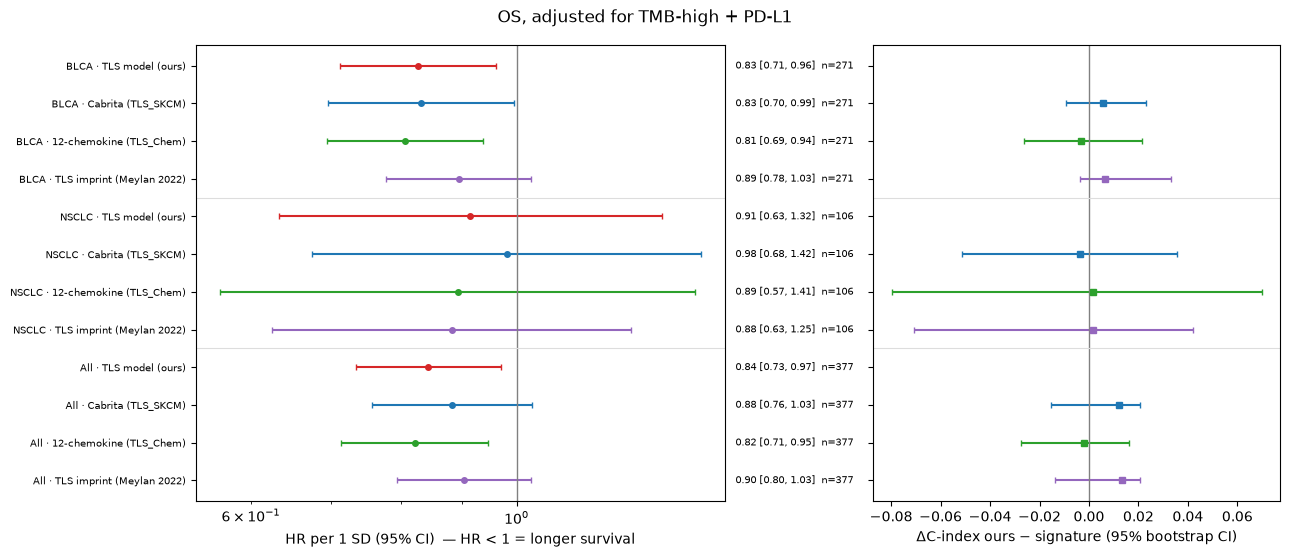

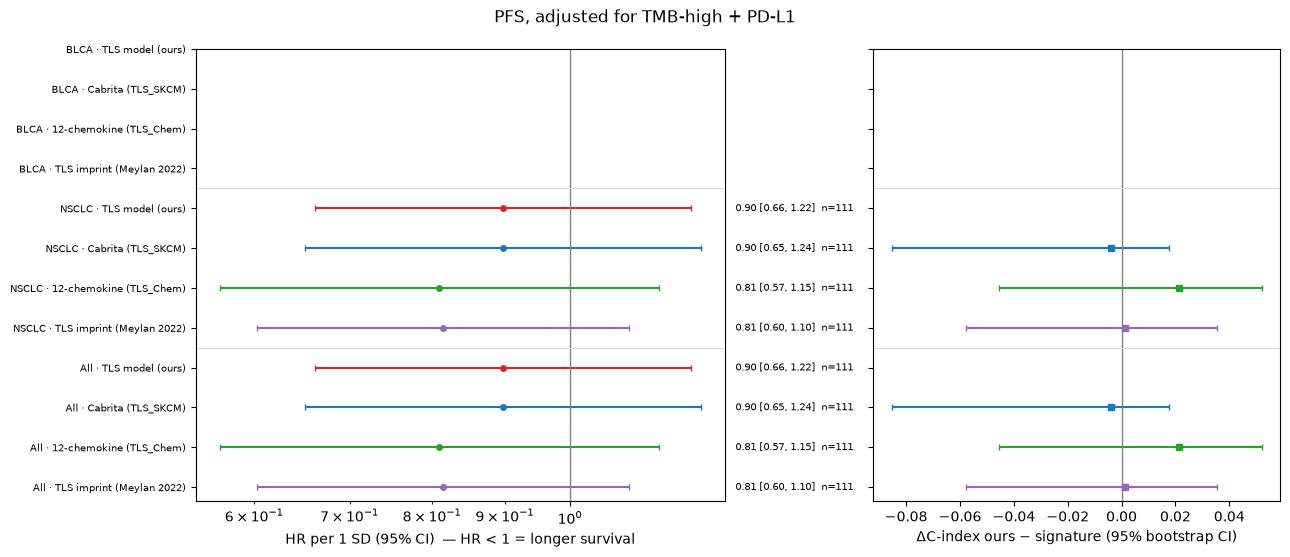

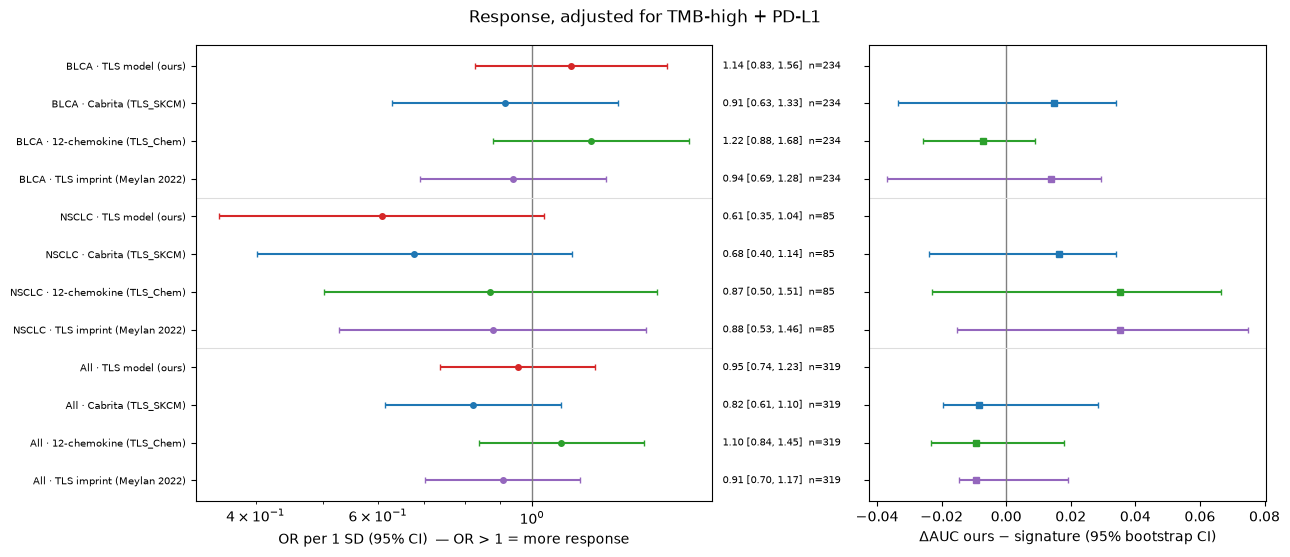

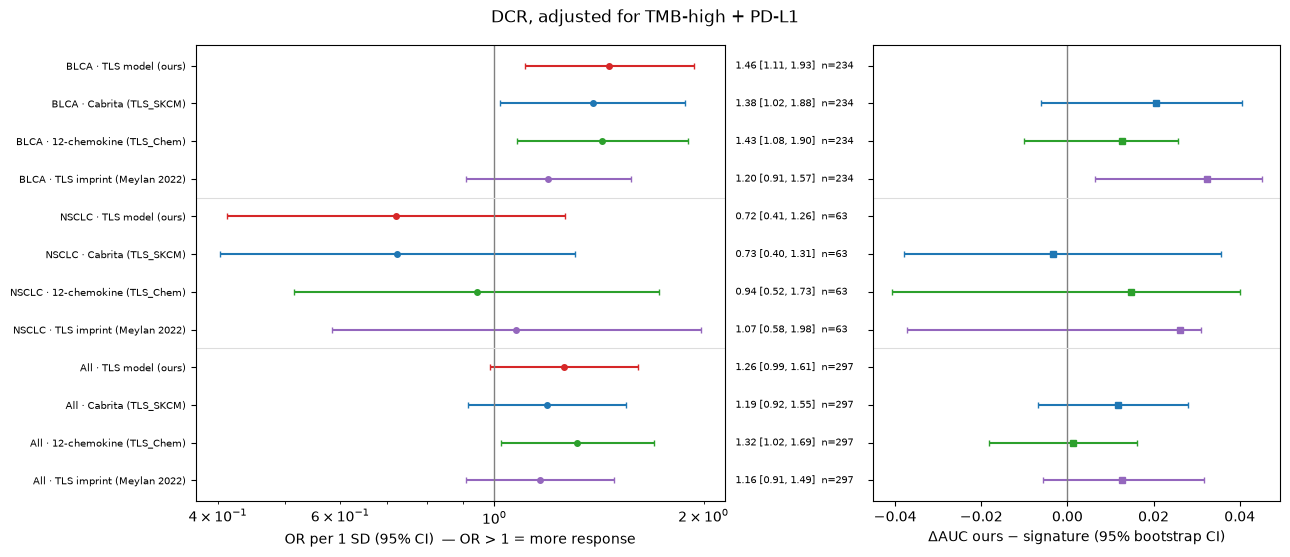

score − (confounders + TMB-high + PD-L1)


reference           12-chemokine (TLS_Chem)       Cabrita (TLS_SKCM) TLS imprint (Meylan 2022)         TLS model (ours)
endpoint diagnosis                                                                                                     
DCR      All        +0.028 [+0.003, +0.045]  +0.017 [-0.006, +0.023]   +0.017 [-0.001, +0.032]  +0.029 [+0.009, +0.038]
         BLCA       +0.036 [+0.003, +0.087]  +0.028 [+0.005, +0.070]   +0.017 [-0.006, +0.068]  +0.049 [+0.010, +0.079]
         NSCLC      +0.009 [-0.011, +0.062]  +0.027 [-0.024, +0.050]   -0.002 [-0.003, +0.051]  +0.024 [-0.012, +0.051]
OS       All        +0.034 [-0.003, +0.058]  +0.020 [+0.001, +0.034]   +0.019 [-0.006, +0.039]  +0.033 [-0.004, +0.052]
         BLCA       +0.024 [-0.000, +0.066]  +0.015 [+0.000, +0.052]   +0.014 [-0.004, +0.046]  +0.021 [+0.006, +0.056]
         NSCLC      +0.001 [-0.046, +0.105]  +0.006 [-0.017, +0.066]   +0.001 [-0.021, +0.077]  +0.003 [-0.028, +0.056]
PFS      All        +0.002 [-0.021, +0.104]  +0.027 [-0.015, +0.150]   +0.022 [-0.033, +0.096]  +0.023 [-0.024, +0.103]
         NSCLC      +0.002 [-0.021, +0.104]  +0.027 [-0.015, +0.150]   +0.022 [-0.033, +0.096]  +0.023 [-0.024, +0.103]
Response All        +0.004 [-0.005, +0.025]  +0.003 [-0.008, +0.028]   +0.004 [-0.006, +0.022]  -0.006 [-0.009, +0.022]
         BLCA       +0.022 [-0.004, +0.045]  -0.000 [-0.014, +0.030]   +0.001 [-0.008, +0.035]  +0.015 [-0.007, +0.040]
         NSCLC      +0.009 [-0.007, +0.062]  +0.028 [-0.004, +0.108]   +0.009 [-0.004, +0.056]  +0.045 [+0.001, +0.114]

In [8]:
nested = ici_report.nested_frame(df)
print(nested.groupby(["diagnosis", "cohort"]).size())
cov_nested = ICI["covariates"] + list(ici_report.NESTED_COVARIATES)
assoc_n, delta_n = ici_report.run_analysis(nested, "nested", SCORES, cov_nested, ici_report.main_pairs(SIGS),
                                           PARTS, ICI["n_boot"], ICI["seed"], subsets=list(ici_report.nested_subsets(nested)))
assoc_n.to_csv(OUT / "assoc_tmb_pdl1.tsv", sep="\t", index=False)
delta_n.to_csv(OUT / "delta_tmb_pdl1.tsv", sep="\t", index=False)
for endpoint in ici_report.ENDPOINTS:
    if assoc_n.loc[assoc_n["endpoint"] == endpoint, "estimate"].notna().any():
        fig = ici_report.forest_plot(assoc_n, delta_n, endpoint, [ici_report.OURS] + SIGS,
                                     title=f"{endpoint}, adjusted for TMB-high + PD-L1")
        fig.savefig(FIG / f"05_forest_tmb_pdl1_{endpoint}.png", dpi=120, bbox_inches="tight")
        plt.show()
print("score − (confounders + TMB-high + PD-L1)")
fmt(delta_n[delta_n["other"] == "covariates only"]).pivot_table(index=["endpoint", "diagnosis"], columns="reference", values="delta", aggfunc="first")

## Added value of our score over the 12-chemokine signature

Nested models, same confounders and same patients (complete cases on every score), per diagnosis and pooled:

* **a** — confounders + 12-chemokine **+ ours** vs confounders + 12-chemokine.
* **b** — confounders + 12-chemokine + ours **+ 12-chemokine × ours** vs confounders + 12-chemokine, and vs **a** (the interaction term alone: both scores read the same biology).
* TMB-high + PD-L1 subset (both as covariates, no interactions with them): **c** ours over TMB + PD-L1; **d** ours over TMB + PD-L1 + 12-chemokine; **e** ours + 12-chemokine × ours over the same base, and vs **d**.

Primary statistic: **likelihood-ratio test** of each nested pair. HR / OR of the added term and ΔC-index / ΔAUC with the paired bootstrap CI (n_boot as above) are descriptive. No correction for multiplicity (diagnoses × endpoints × comparisons) — read the p-values as a screen, not as confirmation.

2026-10-09 12:49:29,671 INFO tls_model.ici_report [1/28] chem_ml BLCA OS START n=347


X:\tls-spatial-bulk\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


2026-10-09 12:49:37,956 INFO tls_model.ici_report [1/28] chem_ml BLCA OS OK


2026-10-09 12:49:37,966 INFO tls_model.ici_report [2/28] chem_ml BLCA PFS START n=0


2026-10-09 12:49:37,998 INFO tls_model.ici_report [2/28] chem_ml BLCA PFS OK


...

2026-10-09 13:02:46,336 INFO tls_model.ici_report [10/12] tmb_pdl1_chem_ml All PFS OK


2026-10-09 13:02:46,344 INFO tls_model.ici_report [11/12] tmb_pdl1_chem_ml All Response START n=319


2026-10-09 13:02:51,702 INFO tls_model.ici_report [11/12] tmb_pdl1_chem_ml All Response OK


2026-10-09 13:02:51,708 INFO tls_model.ici_report [12/12] tmb_pdl1_chem_ml All DCR START n=319


2026-10-09 13:02:56,513 INFO tls_model.ici_report [12/12] tmb_pdl1_chem_ml All DCR OK


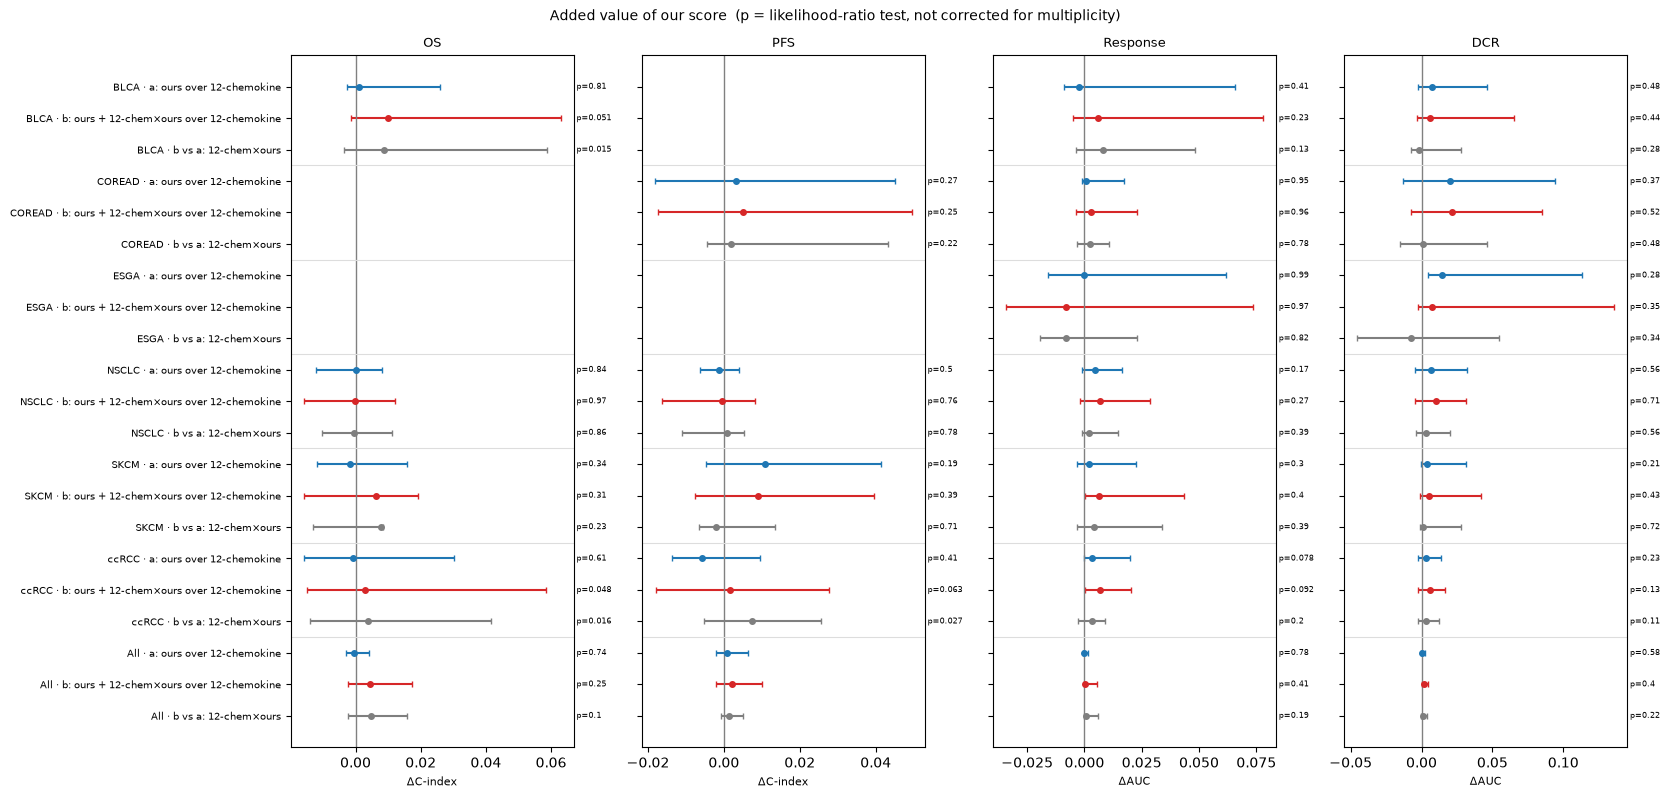

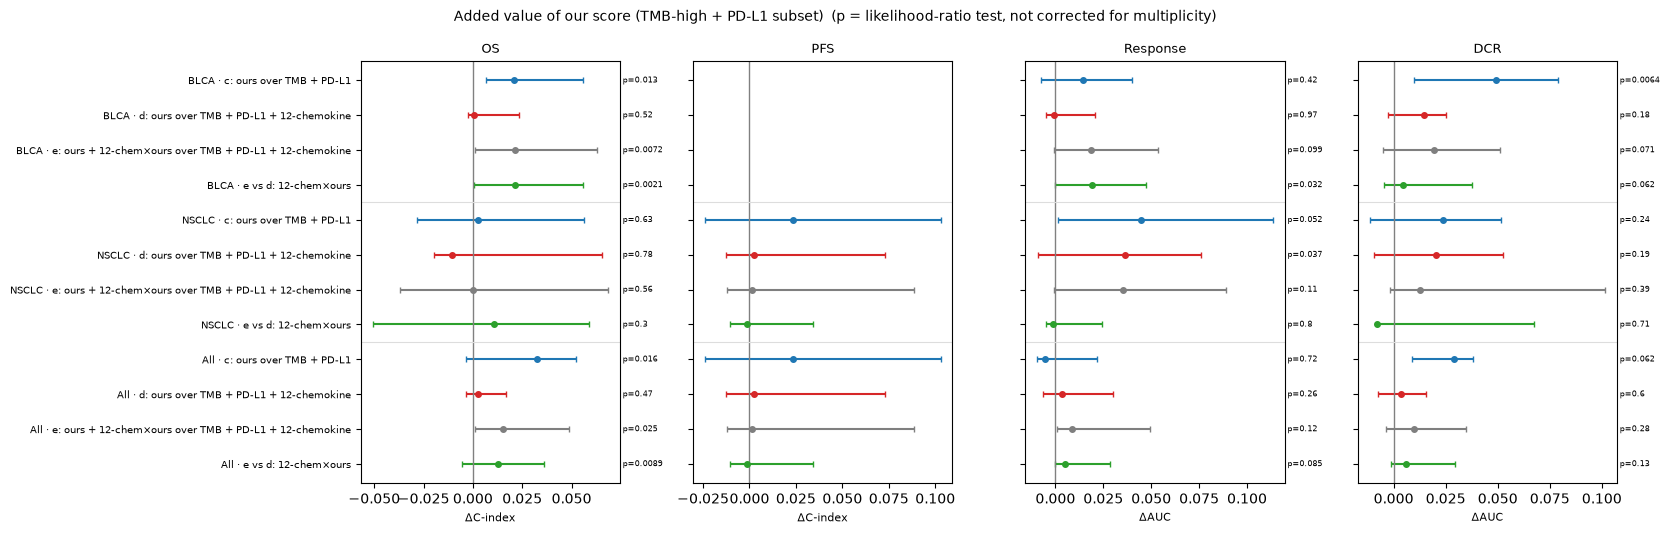

In [9]:
dfx = ici_report.with_interaction(df)
assoc_x, delta_x = ici_report.run_analysis(dfx, "chem_ml", ici_report.ADDED_MODELS, ICI["covariates"],
                                           list(ici_report.ADDED_PAIRS.values()), PARTS, ICI["n_boot"], ICI["seed"])
nested_x = ici_report.nested_frame(dfx)
assoc_nx, delta_nx = ici_report.run_analysis(nested_x, "tmb_pdl1_chem_ml", ici_report.NESTED_ADDED_MODELS, cov_nested,
                                             list(ici_report.NESTED_ADDED_PAIRS.values()), PARTS, ICI["n_boot"], ICI["seed"],
                                             subsets=list(ici_report.nested_subsets(nested_x)))
added = pd.concat([ici_report.label_pairs(delta_x, ici_report.ADDED_PAIRS),
                   ici_report.label_pairs(delta_nx, ici_report.NESTED_ADDED_PAIRS)], ignore_index=True)
added_assoc = pd.concat([assoc_x, assoc_nx], ignore_index=True)
added.to_csv(OUT / "delta_added_value.tsv", sep="\t", index=False)
added_assoc.to_csv(OUT / "assoc_added_value.tsv", sep="\t", index=False)
for name, data, labels in (("chem", added[added["analysis"] == "chem_ml"], ici_report.ADDED_PAIRS),
                           ("tmb_pdl1_chem", added[added["analysis"] == "tmb_pdl1_chem_ml"], ici_report.NESTED_ADDED_PAIRS)):
    fig = ici_report.added_value_plot(data, list(labels), "Added value of our score" + (" (TMB-high + PD-L1 subset)" if "tmb" in name else ""))
    fig.savefig(FIG / f"05_added_value_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

### Table: Δ (bootstrap CI) and LRT p per comparison

In [10]:
cell = lambda r: f"{r.delta:+.3f} [{r.delta_lo:+.3f}, {r.delta_hi:+.3f}]  p={r.lr_p:.2g}" if pd.notna(r.delta) else ""
added.assign(cell=added.apply(cell, axis=1)).pivot_table(index=["endpoint", "diagnosis"], columns="comparison", values="cell", aggfunc="first")

comparison                 a: ours over 12-chemokine              b vs a: 12-chem×ours b: ours + 12-chem×ours over 12-chemokine           c: ours over TMB + PD-L1  \
endpoint diagnosis                                                                                                                                                   
DCR      All         +0.000 [-0.000, +0.002]  p=0.58   +0.001 [-0.000, +0.004]  p=0.22           +0.002 [+0.000, +0.005]  p=0.4   +0.029 [+0.009, +0.038]  p=0.062   
         BLCA        +0.007 [-0.002, +0.046]  p=0.48   -0.002 [-0.008, +0.028]  p=0.28          +0.006 [-0.003, +0.065]  p=0.44  +0.049 [+0.010, +0.079]  p=0.0064   
         COREAD      +0.020 [-0.013, +0.094]  p=0.37   +0.001 [-0.015, +0.046]  p=0.48          +0.021 [-0.008, +0.085]  p=0.52                                NaN   
         ESGA        +0.014 [+0.005, +0.113]  p=0.28   -0.007 [-0.045, +0.055]  p=0.34          +0.007 [-0.002, +0.136]  p=0.35                                NaN   
         NSCLC       +0.007 [-0.005, +0.032]  p=0.56   +0.003 [-0.004, +0.020]  p=0.56          +0.010 [-0.004, +0.031]  p=0.71    +0.024 [-0.012, +0.051]  p=0.24   
         SKCM        +0.004 [-0.001, +0.032]  p=0.21   +0.001 [-0.001, +0.028]  p=0.72          +0.005 [-0.001, +0.042]  p=0.43                                NaN   
         ccRCC       +0.003 [-0.003, +0.014]  p=0.23   +0.003 [-0.002, +0.012]  p=0.11          +0.006 [-0.002, +0.017]  p=0.13                                NaN   
OS       All         -0.000 [-0.003, +0.004]  p=0.74    +0.005 [-0.002, +0.016]  p=0.1          +0.004 [-0.002, +0.017]  p=0.25   +0.033 [-0.004, +0.052]  p=0.016   
         BLCA        +0.001 [-0.003, +0.026]  p=0.81  +0.009 [-0.003, +0.059]  p=0.015         +0.010 [-0.001, +0.063]  p=0.051   +0.021 [+0.006, +0.056]  p=0.013   
         NSCLC       +0.000 [-0.012, +0.008]  p=0.84   -0.000 [-0.010, +0.011]  p=0.86          -0.000 [-0.016, +0.012]  p=0.97    +0.003 [-0.028, +0.056]  p=0.63   
         SKCM        -0.002 [-0.012, +0.016]  p=0.34   +0.008 [-0.013, +0.008]  p=0.23          +0.006 [-0.016, +0.019]  p=0.31                                NaN   
         ccRCC       -0.001 [-0.016, +0.030]  p=0.61  +0.004 [-0.014, +0.042]  p=0.016         +0.003 [-0.015, +0.059]  p=0.048                                NaN   
PFS      All          +0.001 [-0.002, +0.006]  p=nan    +0.001 [-0.001, +0.005]  p=nan           +0.002 [-0.002, +0.010]  p=nan     +0.023 [-0.024, +0.103]  p=nan   
         COREAD      +0.003 [-0.018, +0.045]  p=0.27   +0.002 [-0.004, +0.043]  p=0.22          +0.005 [-0.017, +0.050]  p=0.25                                NaN   
         NSCLC        -0.001 [-0.006, +0.004]  p=0.5   +0.001 [-0.011, +0.005]  p=0.78          -0.001 [-0.016, +0.008]  p=0.76     +0.023 [-0.024, +0.103]  p=nan   
         SKCM        +0.011 [-0.005, +0.041]  p=0.19   -0.002 [-0.006, +0.013]  p=0.71          +0.009 [-0.008, +0.040]  p=0.39                                NaN   
         ccRCC       -0.006 [-0.014, +0.010]  p=0.41  +0.007 [-0.005, +0.026]  p=0.027         +0.002 [-0.018, +0.028]  p=0.063                                NaN   
Response All         -0.000 [-0.000, +0.001]  p=0.78   +0.001 [-0.000, +0.006]  p=0.19          +0.000 [-0.000, +0.005]  p=0.41    -0.006 [-0.009, +0.022]  p=0.72   
         BLCA        -0.002 [-0.009, +0.066]  p=0.41   +0.008 [-0.004, +0.048]  p=0.13          +0.006 [-0.005, +0.078]  p=0.23    +0.015 [-0.007, +0.040]  p=0.42   
         COREAD      +0.001 [-0.001, +0.017]  p=0.95   +0.002 [-0.003, +0.011]  p=0.78          +0.003 [-0.004, +0.023]  p=0.96                                NaN   
         ESGA        +0.000 [-0.016, +0.062]  p=0.99   -0.008 [-0.019, +0.023]  p=0.82          -0.008 [-0.034, +0.074]  p=0.97                                NaN   
         NSCLC       +0.005 [-0.001, +0.017]  p=0.17   +0.002 [-0.001, +0.014]  p=0.39          +0.007 [-0.002, +0.028]  p=0.27   +0.045 [+0.001, +0.114]  p=0.052   
         SKCM   

### HR / OR of the added term (ours in a / d, the 12-chemokine × ours product in b / e)

In [11]:
effect = lambda r: f"{r.estimate:.2f} [{r.lo:.2f}, {r.hi:.2f}]" if pd.notna(r.estimate) else r.note
big = added_assoc[added_assoc["score"].str.count(r"\+") >= 1]
big.assign(effect=big.apply(effect, axis=1)).pivot_table(index=["analysis", "endpoint", "diagnosis"], columns="score", values="effect", aggfunc="first")

score                               12-chemokine (TLS_Chem) + TLS model (ours) 12-chemokine (TLS_Chem) + TLS model (ours) + 12-chemokine × ours
analysis         endpoint diagnosis                                                                                                            
chem_ml          DCR      All                                0.96 [0.85, 1.10]                                  1.07 [0.96, 1.18]              
                          BLCA                               1.11 [0.82, 1.51]                                  1.13 [0.90, 1.42]              
                          COREAD                             1.26 [0.75, 2.10]                                  0.86 [0.57, 1.29]              
                          ESGA                               1.63 [0.67, 3.99]                                  1.48 [0.65, 3.36]              
                          NSCLC                              0.90 [0.62, 1.30]                                  0.91 [0.67, 1.24]              
                          SKCM                               0.82 [0.60, 1.12]                                  1.05 [0.82, 1.34]              
                          ccRCC                              0.88 [0.72, 1.08]                                  1.14 [0.97, 1.34]              
                 OS       All                                1.01 [0.93, 1.10]                                  0.95 [0.89, 1.01]              
                          BLCA                               0.98 [0.82, 1.17]                                  0.85 [0.74, 0.97]              
                          COREAD                            too few events (0)                                 too few events (0)              
                          ESGA                              too few events (0)                                 too few events (0)              
                          NSCLC                              1.01 [0.90, 1.14]                                  0.99 [0.89, 1.10]              
                          SKCM                               0.89 [0.69, 1.14]                                  1.12 [0.94, 1.35]              
                          ccRCC                              1.05 [0.86, 1.28]                                  0.84 [0.73, 0.98]              
                 PFS      All                                1.01 [0.95, 1.08]                                  0.98 [0.93, 1.03]              
                          BLCA                              too few events (0)                                 too few events (0)              
                          COREAD                             0.84 [0.61, 1.15]                                  1.16 [0.93, 1.45]              
                          ESGA                              too few events (0)                                 too few events (0)              
                          NSCLC                              1.04 [0.94, 1.14]                                  0.99 [0.90, 1.08]              
                          SKCM                               1.18 [0.92, 1.50]                                  1.04 [0.86, 1.24]              
                          ccRCC                              0.96 [0.87, 1.06]                                  0.92 [0.85, 0.99]              
                 Response All                                0.98 [0.88, 1.10]                                  1.06 [0.97, 1.16]              
                          BLCA                               0.86 [0.61, 1.23]                                  1.22 [0.94, 1.58]              
                          COREAD                             1.01 [0.72, 1.41]                                  1.05 [0.76, 1.44]              
                          ESGA                               0.99 [0.39, 2.51]                                  0.83 [0.17, 4.13]              
                          NSCLC                              0.87 [0.71, 1.06]                                  